# The Modern Data Stack & ELT Physics

**Data engineering** moves data from the systems where it is created (applications, devices, files, APIs) to the places where it is analysed and used by models, reliably and on time. The **modern data stack** does this with separate, replaceable tools for ingestion, storage, transformation, orchestration and quality, around a central warehouse or lakehouse.

**After this lesson you can:**

1. Explain ETL vs ELT and why ELT became the default.
2. Describe the layers of a warehouse: raw, staging, intermediate, marts (bronze/silver/gold).
3. Build a small but complete ELT pipeline into a DuckDB warehouse and measure each step.
4. Reason about the "physics" of pipelines: volume, latency, cost, idempotency.

**Data:** NYC TLC yellow taxi trips (January–February 2024, 6 million rows) and the taxi zone lookup.

In [1]:
import sys
import tempfile
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
WORK = Path(tempfile.mkdtemp())                   # all warehouses and projects of this lesson live here

print("DuckDB", duckdb.__version__)

DuckDB 1.5.6


## 1. ETL vs ELT

| | ETL (extract, transform, load) | ELT (extract, load, transform) |
| :--- | :--- | :--- |
| where transformations run | a separate engine before loading | **inside the warehouse**, after loading |
| raw data kept? | often not | yes: re-run any transformation later |
| typical era | on-premise warehouses, expensive storage | cloud warehouses, cheap storage, elastic compute |
| tools | Informatica, SSIS, custom scripts | Fivetran/Airbyte/dlt + dbt + Snowflake/BigQuery/DuckDB |

The modern data stack in one picture:

| Layer | Job | Open-source tools in this module |
| :--- | :--- | :--- |
| ingestion | copy data from sources | dlt (Lesson 04) |
| storage | warehouse / lakehouse | DuckDB, PostgreSQL (M07), Iceberg/Delta (M12) |
| transformation | SQL models with tests | dbt (Lesson 03) |
| orchestration | schedule and monitor | Airflow (Lessons 05–07), Dagster (Lesson 08) |
| quality | tests and contracts | dbt tests, Great Expectations (Lesson 10), pandera (M10) |
| consumption | BI, ML, reverse ETL | M09, M16 |

## 2. Warehouse Layers

| Layer | Also called | Content | Rule |
| :--- | :--- | :--- | :--- |
| **raw** | bronze, landing | data exactly as received | append only, never edited |
| **staging** | silver | typed, renamed, cleaned, one model per source table | 1:1 with sources |
| **intermediate** | | joins and business logic | reusable building blocks |
| **marts** | gold | tables for one use case (a dashboard, a model) | documented, tested |

## 3. Build a Mini ELT Pipeline

**Extract + Load:** copy the source files into the `raw` schema of a DuckDB warehouse, unchanged, with load metadata.

In [2]:
wh = duckdb.connect(str(WORK / "warehouse.duckdb"))
wh.execute("SET enable_progress_bar = false")              # no progress widget in the notebook output
for schema in ["raw", "staging", "marts"]:
    wh.execute(f"CREATE SCHEMA IF NOT EXISTS {schema}")

timings = {}
t = time.perf_counter()
months = ["2024-01", "2024-02"]
wh.execute("DROP TABLE IF EXISTS raw.yellow_trips")
for i, month in enumerate(months):
    src = str(datasets.taxi(month))
    verb = "CREATE TABLE raw.yellow_trips AS" if i == 0 else "INSERT INTO raw.yellow_trips"
    wh.execute(f"{verb} SELECT *, '{month}' AS _source_file, now() AS _loaded_at FROM read_parquet('{src}')")
wh.execute(f"CREATE OR REPLACE TABLE raw.taxi_zones AS SELECT *, now() AS _loaded_at FROM read_csv_auto('{datasets.fetch('taxi_zone_lookup.csv')}')")
timings["extract + load (raw)"] = time.perf_counter() - t
print(wh.sql("SELECT _source_file, count(*) AS rows FROM raw.yellow_trips GROUP BY 1 ORDER BY 1").df())

  _source_file     rows
0      2024-01  2964624
1      2024-02  3007526


**Transform (staging):** rename columns to a consistent style, cast types, decode codes, and filter impossible records. Raw data stays untouched, so the rules can be changed and re-run at any time.

In [3]:
t = time.perf_counter()
wh.execute("""
CREATE OR REPLACE TABLE staging.trips AS
SELECT
    tpep_pickup_datetime                                     AS pickup_at,
    tpep_dropoff_datetime                                    AS dropoff_at,
    PULocationID::INTEGER                                    AS pickup_zone_id,
    DOLocationID::INTEGER                                    AS dropoff_zone_id,
    trip_distance                                            AS distance_mi,
    date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) / 60.0 AS duration_min,
    fare_amount, tip_amount, total_amount,
    CASE payment_type WHEN 1 THEN 'card' WHEN 2 THEN 'cash' WHEN 3 THEN 'no charge' WHEN 4 THEN 'dispute'
                      ELSE 'other' END                       AS payment,
    _source_file
FROM raw.yellow_trips
WHERE tpep_pickup_datetime >= DATE '2024-01-01' AND tpep_pickup_datetime < DATE '2024-03-01'
  AND fare_amount BETWEEN 3 AND 500 AND trip_distance BETWEEN 0.1 AND 100
  AND date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) BETWEEN 60 AND 10800
""")
wh.execute("""
CREATE OR REPLACE TABLE staging.zones AS
SELECT LocationID::INTEGER AS zone_id, Borough AS borough, Zone AS zone, service_zone FROM raw.taxi_zones
""")
timings["transform: staging"] = time.perf_counter() - t

t = time.perf_counter()
wh.execute("""
CREATE OR REPLACE TABLE marts.daily_zone_revenue AS
SELECT CAST(t.pickup_at AS DATE) AS day, z.borough, z.zone,
       count(*) AS trips, round(sum(t.total_amount), 2) AS revenue,
       round(avg(CASE WHEN t.payment = 'card' THEN 100 * t.tip_amount / t.fare_amount END), 2) AS card_tip_pct
FROM staging.trips t JOIN staging.zones z ON z.zone_id = t.pickup_zone_id
GROUP BY ALL
""")
timings["transform: mart"] = time.perf_counter() - t
counts = wh.sql("""SELECT 'raw.yellow_trips' AS tbl, count(*) AS n FROM raw.yellow_trips UNION ALL
                   SELECT 'staging.trips', count(*) FROM staging.trips UNION ALL
                   SELECT 'marts.daily_zone_revenue', count(*) FROM marts.daily_zone_revenue""").df()
print(counts.to_string(index=False))
print({k: f"{v:.1f} s" for k, v in timings.items()})

                     tbl       n
        raw.yellow_trips 5972150
           staging.trips 5741632
marts.daily_zone_revenue   13168
{'extract + load (raw)': '17.6 s', 'transform: staging': '8.6 s', 'transform: mart': '0.9 s'}


## 4. Use the Mart

A mart answers its use case with a simple query. The dashboard team no longer needs to know about raw payment codes or broken timestamps.

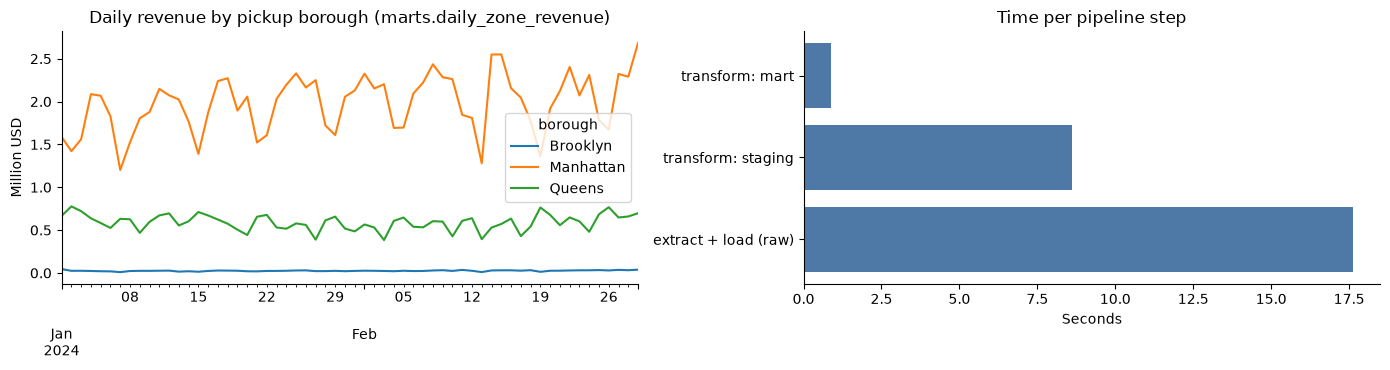

In [4]:
by_borough = wh.sql("""SELECT day, borough, sum(revenue) / 1e6 AS revenue_musd FROM marts.daily_zone_revenue
                       WHERE borough IN ('Manhattan', 'Queens', 'Brooklyn') GROUP BY ALL ORDER BY day""").df()
pivot = by_borough.pivot(index="day", columns="borough", values="revenue_musd")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 3.8))
pivot.plot(ax=ax1)
ax1.set(title="Daily revenue by pickup borough (marts.daily_zone_revenue)", ylabel="Million USD", xlabel="")
ax2.barh(list(timings), list(timings.values()), color="#4E79A7")
ax2.set(title="Time per pipeline step", xlabel="Seconds")
plt.tight_layout()
plt.show()

## 5. Pipeline Physics

| Property | Question | In this pipeline |
| :--- | :--- | :--- |
| **volume** | how much data per run? | ~6 M rows, ~100 MB compressed |
| **latency** | how fresh must the result be? | daily is enough for revenue reporting |
| **idempotency** | does re-running give the same result? | yes: `CREATE OR REPLACE` / full reload (Lesson 09 covers incremental) |
| **cost** | what does a run cost? | seconds of local CPU; in the cloud: bytes scanned (M07 L19) |
| **lineage** | where does each column come from? | raw → staging → marts, visible in the SQL (and in dbt docs, Lesson 03) |
| **recoverability** | can we rebuild after a bug? | yes: raw data is kept unchanged |

In [5]:
before = wh.sql("SELECT sum(revenue) FROM marts.daily_zone_revenue").fetchone()[0]
wh.execute("CREATE OR REPLACE TABLE marts.daily_zone_revenue AS SELECT * FROM marts.daily_zone_revenue")   # re-run: same result
after = wh.sql("SELECT sum(revenue) FROM marts.daily_zone_revenue").fetchone()[0]
size_mb = (WORK / "warehouse.duckdb").stat().st_size / 1e6
print(f"idempotent re-run: {before == after} | warehouse file: {size_mb:.0f} MB")
wh.close()

idempotent re-run: True | warehouse file: 328 MB


*Insight: Land data raw and unchanged, transform it inside the warehouse in layers (staging → marts), and make every step idempotent. Then any bug can be fixed by changing a transformation and re-running it, without going back to the source systems.*

## Real-World Use Case or Analogy

ELT is like a **restaurant that stores all deliveries in the cold room first** (raw), then prepares ingredients (staging) and cooks dishes to order (marts). If a recipe changes, the cook does not reorder from the farm: the ingredients are already there.

Most companies that adopted cloud warehouses after 2015 moved from ETL to ELT for exactly this reason; the "analytics engineer" role (dbt, Lesson 03) emerged from it.